# Semelhança entre as features do EPOC X e do ds004504

Os registros do EPOC X ainda não têm rótulos, então não dá para medir se um modelo acerta. A
pergunta aqui é anterior: **as features do EPOC X se parecem com as do ds004504?** E, quando
diferem, a diferença é maior ou menor que o efeito da doença?

| Seção | Pergunta |
|---|---|
| 1 | Em cada feature, quanto o EPOC X difere dos controles do ds004504, comparado ao efeito AD contra controle? |
| 2 | Cada feature é estável dentro da mesma gravação? |
| 3 | No conjunto das features, as bases se distinguem? Cada gravação do EPOC X é típica de um controle? |
| 4 | As features se relacionam entre si da mesma forma nas duas bases? |
| 5 | (exploratório) O que os modelos treinados no ds004504 preveem para o EPOC X? |

**Como interpretar.** A unidade é a gravação (média das épocas). Com poucas gravações, dá para
afirmar que uma feature **difere** entre as bases, mas não que ela é **igual**: confirmar que a
diferença é menor que 0,5 desvio-padrão exige cerca de 35 gravações do EPOC X. Além disso,
diferenças entre as bases misturam equipamento, protocolo e **quem foi gravado**: se as pessoas do
EPOC X forem mais jovens que as do ds004504, parte da diferença virá da idade.

In [18]:
import importlib
S = importlib.reload(S)

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "feature_sets.py").exists())
EPOCX_ROOT = PROJECT_ROOT / "epocx"
for p in (str(PROJECT_ROOT), str(EPOCX_ROOT)):
    if p not in sys.path:
        sys.path.insert(0, p)

import config_epocx as CFG
import feature_similarity as S
from feature_sets import ALL_FEATURES, FEATURE_SETS

OUT = EPOCX_ROOT / "comparacao"
OUT.mkdir(exist_ok=True)

ds_ep, ep_ep = S.load_tables(EPOCX_ROOT, CFG.feature_tag())
ds = S.recording_table(ds_ep)
ep = S.recording_table(ep_ep)
print("identificador:", CFG.feature_tag())
print(f"ds004504: {len(ds)} sujeitos ({(ds['Group'] == 'A').sum()} AD, {(ds['Group'] == 'C').sum()} CN)")
n_rec = ep_ep["Recording_ID"].nunique() if "Recording_ID" in ep_ep else len(ep)
print(f"EPOC X  : {len(ep)} participantes, {n_rec} gravações, {len(ep_ep)} épocas")
if len(ep) < 35:
    print(f"\nATENÇÃO: com {len(ep)} participantes, diferenças pequenas não são detectáveis e nenhuma feature "
          "pode ser declarada igual entre as bases; só diferenças grandes são conclusivas.")

identificador: v3.0-mastoid-epocx_comum-128Hz
ds004504: 65 sujeitos (36 AD, 29 CN)
EPOC X  : 14 participantes, 28 gravações, 2177 épocas

ATENÇÃO: com 14 participantes, diferenças pequenas não são detectáveis e nenhuma feature pode ser declarada igual entre as bases; só diferenças grandes são conclusivas.


## 1. Feature por feature

Cada feature é classificada pelo g de Hedges entre o EPOC X e os controles do ds004504:

- **compatível com os controles:** |g| < 0,5;
- **deslocada, dentro do efeito da doença:** |g| ≥ 0,5, mas não maior que o efeito AD contra controle no ds004504;
- **deslocamento maior que o efeito da doença:** a diferença entre as bases supera o efeito da doença; para essa feature, um modelo treinado no ds004504 provavelmente não funciona no EPOC X.

`classificacao_incerta = True` indica que o IC95% do g cruza o limite de 0,5: a categoria depende
do acaso da amostra. `posicao_CN_AD` mostra onde a mediana do EPOC X fica entre os grupos do
ds004504 (0 = como os controles, 1 = como os pacientes); só é calculada quando o efeito da doença é
pelo menos pequeno.

classificacao_incerta                      conclusiva  incerta
categoria                                                     
compatível com os controles                         0       12
deslocada, dentro do efeito da doença               0        2
deslocamento maior que o efeito da doença          12        5


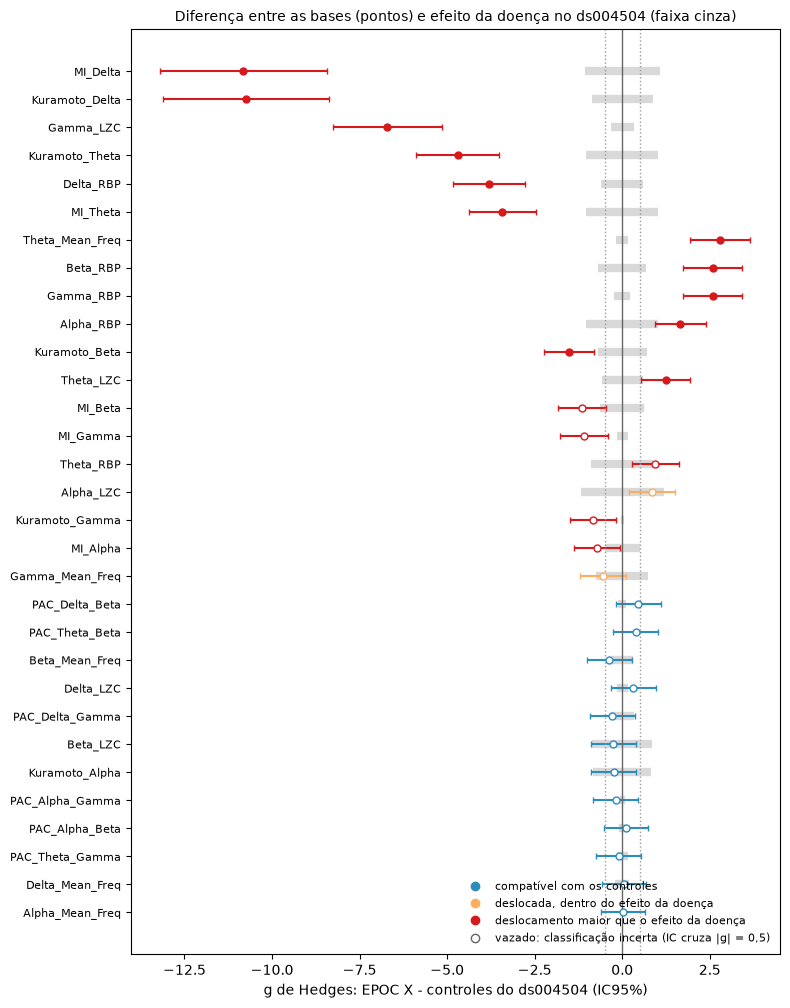

,feature,g_EPOC_vs_CN,g_IC_inf,g_IC_sup,d_AD_vs_CN,g_EPOC_vs_AD,posicao_CN_AD,AUC_EPOC_vs_CN,p_KS_BH,categoria,classificacao_incerta
7,Alpha_Mean_Freq,0.027,-0.611,0.665,-0.036,0.068,NaN,0.537,0.408,compatível com os controles,True
5,Delta_Mean_Freq,0.051,-0.587,0.689,0.204,-0.036,NaN,0.458,0.079,compatível com os controles,True
18,PAC_Theta_Gamma,-0.098,-0.736,0.540,-0.156,0.090,NaN,0.557,0.828,compatível com os controles,True
19,PAC_Alpha_Beta,0.106,-0.532,0.745,-0.088,0.208,NaN,0.539,0.434,compatível com os controles,True
20,PAC_Alpha_Gamma,-0.187,-0.826,0.452,-0.074,-0.084,NaN,0.438,0.827,compatível com os controles,True
23,Kuramoto_Alpha,-0.239,-0.878,0.401,0.821,-1.131,-0.093,0.453,0.794,compatível com os controles,True
13,Beta_LZC,-0.254,-0.894,0.386,0.864,-1.067,-0.297,0.446,0.745,compatível com os controles,True
16,PAC_Delta_Gamma,-0.282,-0.923,0.358,-0.338,0.044,NaN,0.431,0.233,compatível com os controles,True
10,Delta_LZC,0.310,-0.331,0.952,0.160,0.269,NaN,0.510,0.290,compatível com os controles,True
8,Beta_Mean_Freq,-0.365,-1.007,0.278,-0.308,-0.057,NaN,0.429,0.622,compatível com os controles,True


In [2]:
tab = S.per_feature_table(ds, ep)
tab.to_csv(OUT / "comparacao_por_feature.csv", index=False)

print(pd.crosstab(tab["categoria"], tab["classificacao_incerta"].map({False: "conclusiva", True: "incerta"})).to_string())
fig = S.plot_shift_vs_disease(tab, OUT / "deslocamento_vs_doenca.png")
plt.show()
tab[["feature", "g_EPOC_vs_CN", "g_IC_inf", "g_IC_sup", "d_AD_vs_CN", "g_EPOC_vs_AD",
     "posicao_CN_AD", "AUC_EPOC_vs_CN", "p_KS_BH", "categoria", "classificacao_incerta"]] \
    .sort_values("g_EPOC_vs_CN", key=np.abs).round(3)

## 2. Confiabilidade dentro da gravação

Para cada gravação, a média da primeira metade do registro é comparada com a da segunda
(correlação entre gravações, corrigida para o registro inteiro). Uma feature pouco confiável no
EPOC X não pode ser considerada "igual" ou "diferente" com segurança, porque varia demais dentro da
mesma pessoa. Valores acima de ~0,7 são em geral considerados aceitáveis.

No EPOC X, quem tem duas gravações de olhos fechados permite também a confiabilidade
**teste-reteste** (`r_entre_runs`): a mesma feature medida em duas gravações separadas, com o
aparelho recolocado. É uma medida mais exigente que a divisão de uma gravação ao meio.
`confiabilidade_media_2_runs` vale para a média das duas gravações, que é o que entra nas
comparações.

In [3]:
rel = S.split_half_reliability(ds_ep).merge(S.split_half_reliability(ep_ep), on="feature",
                                            suffixes=("_ds004504", "_EPOC"))
runs = S.run_reliability(ep_ep)
if runs is not None:
    rel = rel.merge(runs[["feature", "r_entre_runs", "confiabilidade_media_2_runs"]], on="feature")
    print(f"teste-reteste no EPOC X: {runs['n_participantes'].iloc[0]} participantes com duas gravações")
rel.to_csv(OUT / "confiabilidade.csv", index=False)
print("features com confiabilidade < 0,7 no EPOC X:",
      rel.loc[rel["confiabilidade_EPOC"] < 0.7, "feature"].tolist() or "nenhuma")
cols = ["feature", "confiabilidade_ds004504", "confiabilidade_EPOC", "n_EPOC"] + \
       [c for c in ("r_entre_runs", "confiabilidade_media_2_runs") if c in rel]
rel[cols].round(3)

teste-reteste no EPOC X: 14 participantes com duas gravações
features com confiabilidade < 0,7 no EPOC X: nenhuma


,feature,confiabilidade_ds004504,confiabilidade_EPOC,n_EPOC,r_entre_runs,confiabilidade_media_2_runs
0,Delta_RBP,0.953,0.975,28,0.525,0.689
1,Theta_RBP,0.898,0.958,28,0.859,0.924
2,Alpha_RBP,0.980,0.947,28,0.798,0.888
3,Beta_RBP,0.936,0.945,28,0.741,0.851
4,Gamma_RBP,0.859,0.956,28,0.837,0.911
5,Delta_Mean_Freq,0.679,0.950,28,0.323,0.488
6,Theta_Mean_Freq,0.946,0.967,28,0.895,0.944
7,Alpha_Mean_Freq,0.972,0.979,28,0.960,0.980
8,Beta_Mean_Freq,0.933,0.930,28,0.868,0.929
9,Gamma_Mean_Freq,0.910,0.916,28,0.811,0.896


## 3. Visão multivariada

**Classificador de base:** uma regressão logística tenta distinguir as gravações do EPOC X das dos
controles do ds004504, com validação cruzada repetida. AUC perto de 0,5 significa bases
indistinguíveis; perto de 1, bases que se separam com facilidade. É calculado com todas as
features e com cada conjunto.

**Tipicidade:** distância de Mahalanobis de cada gravação à distribuição dos controles do ds004504.
O limite é o percentil 95 dos próprios controles (cada um calculado fora do ajuste). A fração de
pacientes com AD acima do limite mostra quanto essa medida separa os grupos dentro do ds004504.

**Projeção:** componentes principais ajustados só no ds004504, com o EPOC X projetado neles.

In [4]:
linhas = []
for nome, cols in FEATURE_SETS.items():
    r = S.domain_classifier(ds, ep, cols)
    linhas.append({"conjunto": nome, "AUC_media": r["AUC_media"], "AUC_p2_5": r.get("AUC_p2_5"),
                   "AUC_p97_5": r.get("AUC_p97_5")})
dominio = pd.DataFrame(linhas)
dominio.to_csv(OUT / "classificador_de_base.csv", index=False)
print(dominio.round(3).to_string(index=False))

r_all = S.domain_classifier(ds, ep, ALL_FEATURES)
print("\nfeatures que mais separam as bases (coeficientes padronizados):")
print(r_all["coeficientes"].head(8).round(3).to_string())

            conjunto  AUC_media  AUC_p2_5  AUC_p97_5
                 RBP      0.999     1.000        1.0
 Centroide espectral      0.984     0.860        1.0
LZC (banda estreita)      1.000     1.000        1.0
           PAC local      0.584     0.222        1.0
   Kuramoto (sensor)      1.000     1.000        1.0
    Informação mútua      1.000     1.000        1.0
          Todas (31)      1.000     1.000        1.0

features que mais separam as bases (coeficientes padronizados):
Kuramoto_Delta   -0.498
MI_Delta         -0.488
Gamma_LZC        -0.475
Kuramoto_Theta   -0.394
MI_Theta         -0.334
Gamma_RBP         0.331
Beta_RBP          0.319
Delta_RBP        -0.315


{'limite_p95_controles': 56.423, 'frac_tipica_EPOC X': 0.0, 'frac_tipica_ds004504 AD': 0.583, 'frac_tipica_ds004504 CN (fora do ajuste)': 0.931}


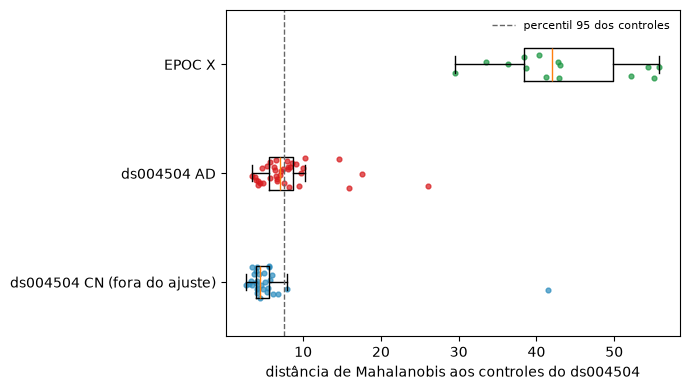

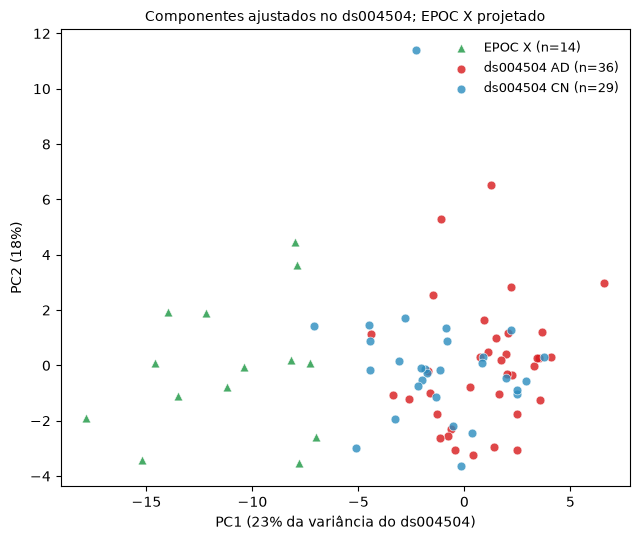

In [7]:
tip, resumo_tip = S.typicality(ds, ep)
tip.to_csv(OUT / "tipicidade.csv", index=False)
print({k: round(v, 3) for k, v in resumo_tip.items()})
S.plot_typicality(tip, resumo_tip["limite_p95_controles"], OUT / "tipicidade.png")
plt.show()

proj, var = S.pca_projection(ds, ep)
S.plot_pca(proj, var, OUT / "pca.png")
plt.show()

In [15]:
print(tip.sort_values("d2", ascending=False).head(5))

   Subject_ID    base           d2  tipico_de_controle
70    sub-122  EPOC X  3114.038908               False
65    sub-012  EPOC X  3035.869159               False
77    sub-312  EPOC X  2959.544318               False
72    sub-152  EPOC X  2718.331306               False
71    sub-151  EPOC X  1848.624740               False


In [16]:
from feature_sets import ALL_FEATURES
subconjuntos = {
    "todas": ALL_FEATURES,
    "sem delta": [f for f in ALL_FEATURES if "Delta" not in f],
    "candidatas": ["Beta_LZC", "Kuramoto_Alpha"],
}
for nome, cols in subconjuntos.items():
    _, r = S.typicality(ds, ep, feature_cols=cols)
    print(f"{nome:11s}: EPOC X típico = {r['frac_tipica_EPOC X']:.0%} | "
          f"AD típico = {r['frac_tipica_ds004504 AD']:.0%} | "
          f"CN típico = {r['frac_tipica_ds004504 CN (fora do ajuste)']:.0%}")

todas      : EPOC X típico = 0% | AD típico = 58% | CN típico = 93%
sem delta  : EPOC X típico = 0% | AD típico = 53% | CN típico = 93%
candidatas : EPOC X típico = 57% | AD típico = 92% | CN típico = 93%


## 4. Estrutura de correlação

Compara as correlações entre todas as features nas duas bases. Perto de 1, as features se
relacionam entre si do mesmo jeito; perto de 0, a estrutura mudou. Com poucas gravações no EPOC X,
as correlações dele são ruidosas e este número tende a sair baixo mesmo sem diferença real.

In [8]:
estrutura = S.correlation_structure(ds, ep)
print(estrutura)

{'r_estrutura': 0.26026719281483623, 'n_pares': 465, 'n_features': 31}


## 5. (Exploratório) Predições dos modelos do ds004504 para o EPOC X

**Não é uma avaliação**: sem rótulos, não há como saber se as predições estão certas. Serve só
como sinal de alerta. Se as gravações do EPOC X forem de pessoas saudáveis e quase todas forem
classificadas como AD, ou se todas caírem na mesma classe, o deslocamento entre as bases domina a
predição, como aconteceu com o BrainLat.

In [11]:
RUN_PREDICTIONS = True
if RUN_PREDICTIONS:
    import modeling as M
    from feature_sets import MODEL_NAMES
    y = (ds["Group"] == "A").astype(int).to_numpy()
    linhas = []
    for model in MODEL_NAMES:
        for nome, cols in FEATURE_SETS.items():
            try:
                pipe = M.make_pipeline(model, y).fit(ds[cols].to_numpy(float), y)
            except ImportError as exc:
                print(f"{model}: {exc}")
                break
            pred = pipe.predict(ep[cols].to_numpy(float))
            linhas.append({"Modelo": model, "Conjunto": nome, "frac_prevista_AD": pred.mean()})
    pred_tab = pd.DataFrame(linhas)
    pred_tab.to_csv(OUT / "predicoes_exploratorias.csv", index=False)
    display(pred_tab.pivot(index="Conjunto", columns="Modelo", values="frac_prevista_AD").round(2))

Modelo,Random Forest,SVM (Linear),XGBoost
Conjunto,,,
Centroide espectral,0.36,0.71,0.43
Informação mútua,1.00,1.00,1.00
Kuramoto (sensor),0.86,1.00,0.64
LZC (banda estreita),0.71,0.64,0.71
PAC local,0.79,0.71,0.50
RBP,0.36,0.07,0.07
Todas (31),0.79,1.00,0.50


## 6. Teste de qual feature se mantém estável

candidatas: ['Beta_LZC', 'Kuramoto_Alpha']
deslocamento comprovadamente menor que o efeito da doença: nenhuma


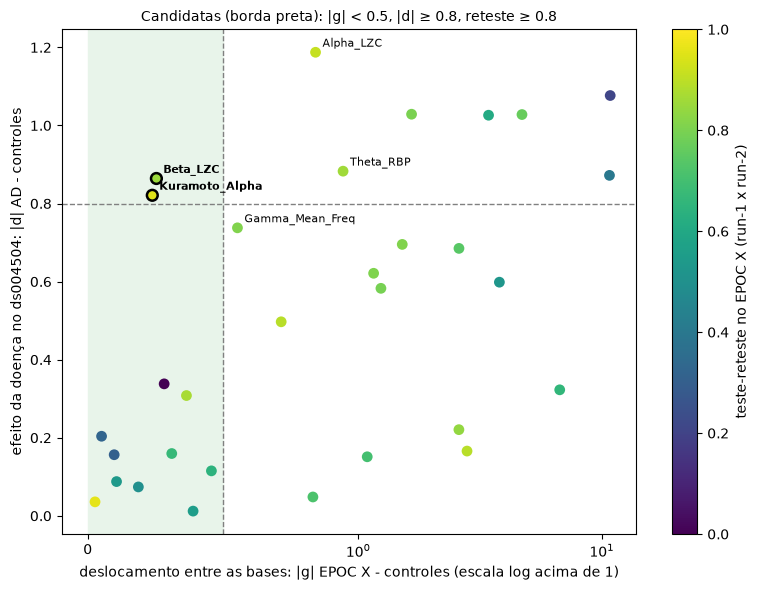

,feature,g_EPOC_vs_CN,g_IC_inf,g_IC_sup,d_AD_vs_CN,r_entre_runs,confiabilidade_ds004504,c1_deslocamento_pequeno,c2_efeito_doenca_grande,c3_estavel_entre_sessoes,n_criterios,candidata,deslocamento_menor_conclusivo
0,Beta_LZC,-0.254,-0.894,0.386,0.864,0.851,0.886,True,True,True,3,True,False
1,Kuramoto_Alpha,-0.239,-0.878,0.401,0.821,0.952,0.968,True,True,True,3,True,False
2,Alpha_LZC,0.842,0.180,1.504,1.187,0.912,0.966,False,True,True,2,False,False
3,Theta_RBP,0.944,0.275,1.612,0.883,0.859,0.898,False,True,True,2,False,False
4,Beta_Mean_Freq,-0.365,-1.007,0.278,-0.308,0.868,0.933,True,False,True,2,False,False
5,Alpha_Mean_Freq,0.027,-0.611,0.665,-0.036,0.960,0.972,True,False,True,2,False,False
6,MI_Delta,-10.816,-13.189,-8.443,-1.077,0.209,0.963,False,True,False,1,False,False
7,Alpha_RBP,1.654,0.926,2.381,-1.029,0.798,0.980,False,True,False,1,False,False
8,Kuramoto_Theta,-4.697,-5.877,-3.517,-1.028,0.767,0.983,False,True,False,1,False,False
9,MI_Theta,-3.424,-4.389,-2.460,-1.026,0.609,0.986,False,True,False,1,False,False


In [13]:
cand = S.candidate_features(tab, rel, max_shift=0.5, min_disease=0.8, min_retest=0.8)
cand.to_csv(OUT / "candidatas.csv", index=False)

print("candidatas:", cand.loc[cand["candidata"], "feature"].tolist() or "nenhuma")
print("deslocamento comprovadamente menor que o efeito da doença:",
      cand.loc[cand["deslocamento_menor_conclusivo"], "feature"].tolist() or "nenhuma")
S.plot_candidates(cand, out_path=OUT / "candidatas.png")
plt.show()
cand.round(3)

In [14]:
import itertools
grade = {"max_shift": [0.4, 0.5, 0.6], "min_disease": [0.7, 0.8, 0.9], "min_retest": [0.7, 0.8, 0.9]}
contagem = {}
for ms, md, mr in itertools.product(*grade.values()):
    c = S.candidate_features(tab, rel, max_shift=ms, min_disease=md, min_retest=mr)
    for f in c.loc[c["candidata"], "feature"]:
        contagem[f] = contagem.get(f, 0) + 1
n = len(list(itertools.product(*grade.values())))
print(f"vezes em que cada feature foi candidata, em {n} combinações de limites:")
for f, k in sorted(contagem.items(), key=lambda x: -x[1]):
    print(f"  {f:16s} {k:2d}/{n}")

vezes em que cada feature foi candidata, em 27 combinações de limites:
  Kuramoto_Alpha   18/27
  Beta_LZC         12/27
  Gamma_Mean_Freq   2/27


In [20]:
importlib.reload(M)

<module 'modeling' from 'C:\\Universidade\\NeuroComp\\Memoria\\ccnec\\modeling.py'>

In [22]:
import warnings; warnings.filterwarnings("ignore", message=r".*sklearn\.utils\.parallel\.delayed.*")

In [23]:
import modeling as M

d2 = ds.assign(y=(ds["Group"] == "A").astype(int))
for model in ["SVM (Linear)", "Random Forest"]:
    p = M.loso_predict(d2, ["Beta_LZC", "Kuramoto_Alpha"], model)
    m = M.metrics(p["y"], p["pred"], p["score"])
    print(f"{model:14s} AUC {m['AUC']:.3f} [{m['AUC_IC_inf']:.3f}; {m['AUC_IC_sup']:.3f}] | "
          f"acurácia {m['Accuracy']:.3f} (classe majoritária {m['Classe_majoritaria']:.3f})")

SVM (Linear)   AUC 0.734 [0.596; 0.849] | acurácia 0.677 (classe majoritária 0.554)
Random Forest  AUC 0.597 [0.452; 0.732] | acurácia 0.600 (classe majoritária 0.554)
